In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from midi_util import convert_midi_to_midi_function
# Load the CSV file
df = pd.read_csv('search_results.csv')
df.head()

,vertical_displacement,horizontal_displacement,scaling_factor,similarity
0,0,0,0.523809,0.313296
1,0,0,0.533333,0.306334
2,0,0,0.542857,0.312400
3,0,0,0.552381,0.324646
4,0,0,0.561904,0.313816


In [173]:
x_axis = df['horizontal_displacement'] 
y_axis = df['scaling_factor'] 
z_axis = df['similarity'] 

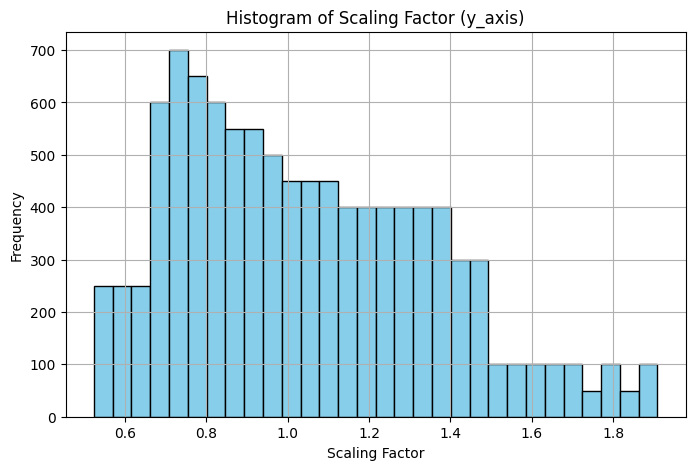

In [175]:
plt.figure(figsize=(8, 5))
plt.hist(y_axis, bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Scaling Factor')
plt.ylabel('Frequency')
plt.title('Histogram of Scaling Factor (y_axis)')
plt.grid(True)
plt.show()

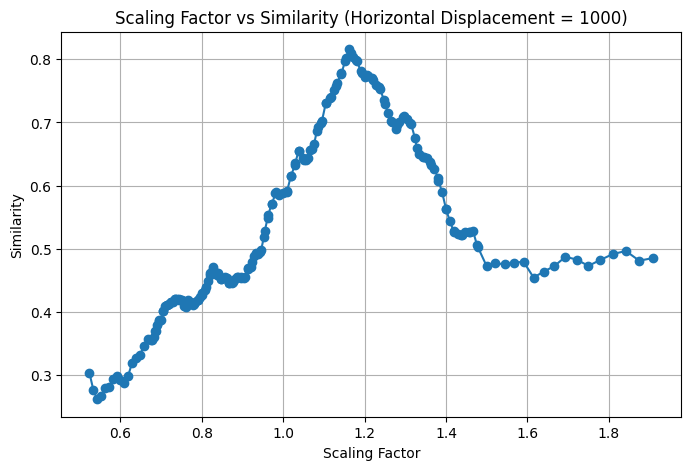

In [ ]:
# Choose a fixed horizontal displacement value, e.g., 1000
fixed_horizontal_displacement = 1000

# Filter the dataframe for the chosen horizontal displacement
filtered_df = df[df['horizontal_displacement'] == fixed_horizontal_displacement]

# Plot scaling_factor vs similarity
plt.figure(figsize=(8, 5))
plt.plot(filtered_df['scaling_factor'], filtered_df['similarity'], marker='o')
plt.xlabel('Scaling Factor')
plt.ylabel('Similarity')
plt.title(f'Scaling Factor vs Similarity (Horizontal Displacement = {fixed_horizontal_displacement})')
plt.grid(True)
plt.show()

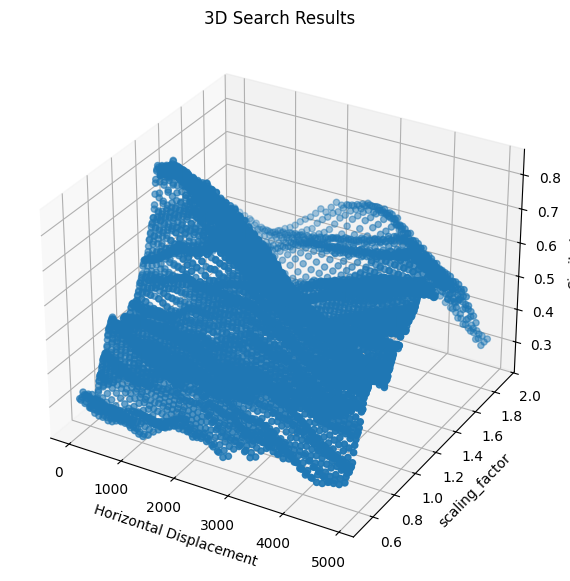

In [ ]:
def plot_3d(x_data, y_data, z_data, title="3D Plot", xlabel="X", ylabel="Y", zlabel="Z"):
    """
    Plots 3D data using matplotlib
    
    Parameters:
    x_data, y_data, z_data: Arrays of data points
    title: Plot title (optional)
    xlabel, ylabel, zlabel: Axis labels (optional)
    """
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(x_data, y_data, z_data)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_zlabel(zlabel)
    
    plt.show()
plot_3d(x_axis, y_axis, z_axis, title="3D Search Results", xlabel="Horizontal Displacement", ylabel="scaling_factor", zlabel="Similarity")


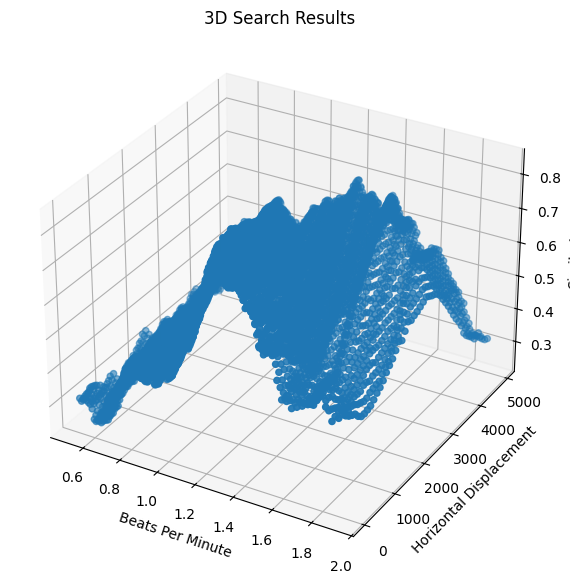

In [ ]:
plot_3d(y_axis, x_axis, z_axis, title="3D Search Results", xlabel="Beats Per Minute", ylabel="Horizontal Displacement", zlabel="Similarity") 

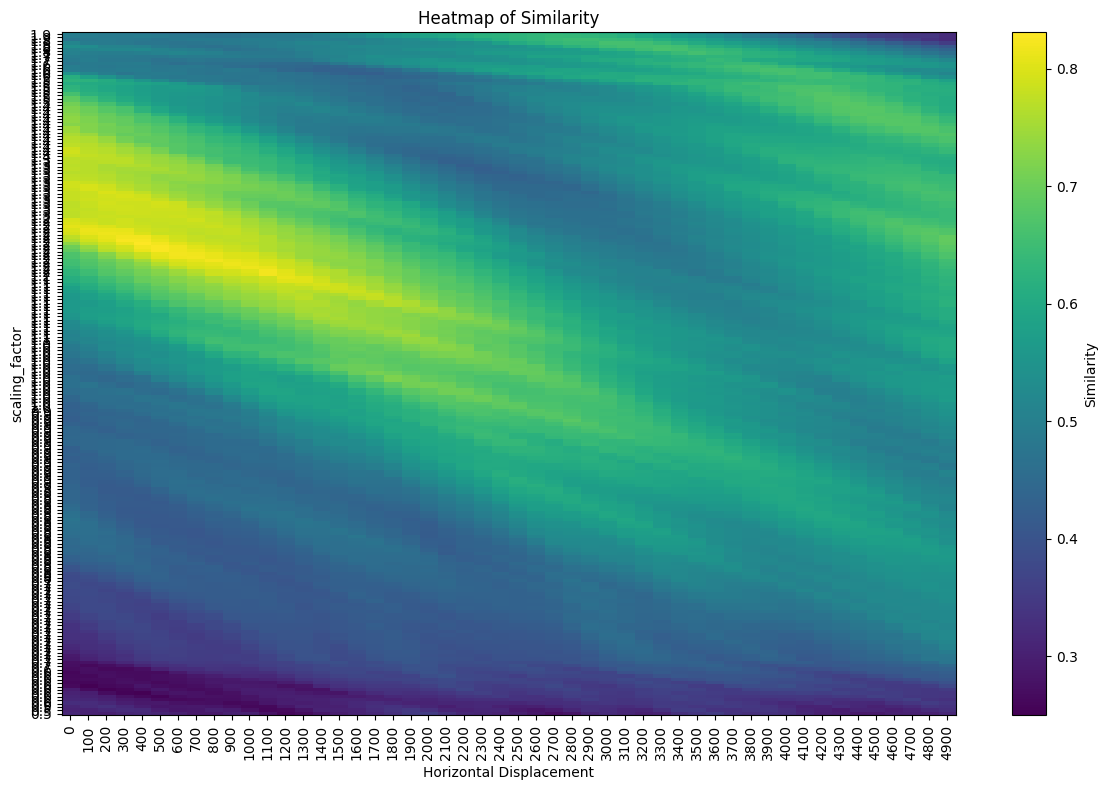

In [ ]:
# Create a pivot table for the heatmap
heatmap_data = df.pivot_table(
    index='scaling_factor',
    columns='horizontal_displacement',
    values='similarity'
)

plt.figure(figsize=(12, 8))
plt.imshow(heatmap_data, aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='Similarity')
plt.xlabel('Horizontal Displacement')
plt.ylabel('scaling_factor')
plt.title('Heatmap of Similarity')
plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns,
    rotation=90
)
plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=np.round(heatmap_data.index, 1)
)
plt.tight_layout()
plt.show()